# Generating missing data

**Missingness** is the defect where some observed values are simply
not recorded (`np.nan` in the output). Real pipelines rarely get to
see complete data: sensors drop out, forms are left blank, values
exceed a recording range. The *mechanism* matters as much as the
amount — the same 20% of missing values behaves very differently
depending on **why** the values are missing:

| Mechanism | Meaning | In badgers (selector) | Legacy one-knob |
|---|---|---|---|
| **MCAR** — missing completely at random | a value goes missing independently of everything else | `BernoulliSelector(rate=...)` | `MissingCompletelyAtRandom` |
| **MAR** — missing at random | missingness depends on **another, observed** variable (e.g. values of `X` are high) | `TopQuantileSelector(..., drivers=...)` | `DummyMissingAtRandom` |
| **MNAR** — missing not at random | a value's **own** (unobserved) magnitude drives its missingness | `TopQuantileSelector` on itself | `DummyMissingNotAtRandom` |
The notebook shows both ways of expressing these mechanisms:

1. **Acting on the observation process** — the legacy one-knob
   generators: `percentage_missing` decides *how much* goes missing,
   the generator class decides *why*. They *do not use a DGP* and
   nothing is propagated.
2. **Explicit selectors** — the same three mechanisms expressed as
   selector objects, which decide *which cells* fire. Intensity
   (`rate` / `quantile`) lives on the selector, not on `generate()`.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from numpy.random import default_rng
from sklearn.datasets import make_blobs

from badgers.generators.tabular_data.missingness import (
    MissingCompletelyAtRandom, DummyMissingAtRandom, DummyMissingNotAtRandom,
)
from badgers.generators.tabular_data.missingness.causal import CausalMissingnessGenerator
from badgers.core.dgp import OlsDGP
from badgers.core.selectors import BernoulliSelector, TopQuantileSelector

rng = default_rng(seed=0)


In [ ]:
def plot_missing(X, cls, Xt):
    """Scatter plots of the original and the transformed data (missing rows marked)."""
    missing_mask = np.isnan(Xt).any(axis=1)
    fig, axes = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(8,4))
    for label in np.unique(cls):
        ix = np.where(cls == label)
        axes[0].scatter(X[ix,0],X[ix,1], c = f'C{label}', label = f'{label}')
        ix = np.where(cls[~missing_mask] == label )
        axes[1].scatter(Xt[~missing_mask][ix,0], Xt[~missing_mask][ix,1], c = f'C{label}', label = f'{label}')
    # plot missing values
    axes[1].scatter(X[missing_mask][:,0],X[missing_mask][:,1],marker='x', color='black', label = 'missing')
    axes[0].set_title('Original')
    axes[1].set_title('Transformed')
    axes[0].legend()
    axes[1].legend()
    return fig, axes


In [ ]:
X, y = make_blobs(centers=4, random_state=0)
# classes are a column of X (y is deprecated as a data carrier)
Xc = np.column_stack([X, y])
cls = Xc[:, 2].astype(int)   # explicit class vector for plotting
print(X.shape)

## Part A — Acting on the observation process (legacy one-knob, no DGP)

These generators take a single `percentage_missing` value: *how much*
goes missing. *Why* it goes missing is hard-coded by the class
(MCAR / MAR / MNAR). No causal model is involved and no propagation
happens.

### Missing completely at random (MCAR)

`MissingCompletelyAtRandom` replaces values with `np.nan`
independently at random — the fact that a value is missing carries no
information.

In [ ]:
gen = MissingCompletelyAtRandom(random_generator=rng)
Xt, _ = gen.generate(X.copy(), None, percentage_missing=0.2)   # y=None (deprecated slot)
print(f'rows with a NaN: {np.isnan(Xt).any(axis=1).sum()} / {len(Xt)}')

In [ ]:
fig, axes = plot_missing(X, cls, Xt)


### Missing at random (MAR)

`DummyMissingAtRandom` makes missingness depend on **another,
observed** feature: for each column, a reference column is drawn
uniformly at random among the *other* columns, and the missing
probability grows as the (normalized, reversed) values of that
reference column. Low values of the reference column go missing first. Looking only at observed data one can
partly *explain* the missingness (it correlates with the reference column), but
it cannot be fully predicted.

In [ ]:
gen = DummyMissingAtRandom(random_generator=rng)
Xt, _ = gen.generate(X.copy(), None, percentage_missing=0.25)
print(f'rows with a NaN: {np.isnan(Xt).any(axis=1).sum()} / {len(Xt)}')

In [ ]:
fig, axes = plot_missing(X, cls, Xt)


### Missing not at random (MNAR)

`DummyMissingNotAtRandom` makes a value's **own** magnitude drive its
missingness (unlike the other two generators, `percentage_missing`
has no default value — pass it explicitly): the larger the original value, the more likely it is
missing. Here the missingness *biases* the observed data — e.g. peak
values systematically vanish.

In [ ]:
gen = DummyMissingNotAtRandom(random_generator=rng)
Xt, _ = gen.generate(X.copy(), None, percentage_missing=0.25)
print(f'rows with a NaN: {np.isnan(Xt).any(axis=1).sum()} / {len(Xt)}')

In [ ]:
fig, axes = plot_missing(X, cls, Xt)


## Part B — Explicit selectors on a causal graph

`CausalMissingnessGenerator` expresses the **same three mechanisms**
with selector objects on a fitted DGP. It writes `NaN` at the affected
cells of the perturbation nodes and does **not** propagate: missingness
is a property of the *measurement* process, not of the data-generating
process (a descendant can still be observed).

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

from badgers.core.dgp import OlsDGP

In [ ]:
def generate_linear_data(graph, n_samples=100, rng=None, coefficients=None):
    """Generate data from a linear structural equation model on a DAG.

    Each edge (u -> v) carries a coefficient w. Every node value is
        v = sum_{u in parents(v)} w_{u,v} * u + noise
    with noise ~ N(0, 1).
    """
    if rng is None:
        rng = np.random.default_rng(42)
    if coefficients is None:
        coefficients = {edge: 1.0 for edge in graph.edges()}

    nodes = list(graph.nodes())
    node_to_idx = {node: i for i, node in enumerate(nodes)}
    X = np.zeros((n_samples, len(nodes)))
    for node in nx.topological_sort(graph):
        idx = node_to_idx[node]
        parents = list(graph.predecessors(node))
        if not parents:
            X[:, idx] = rng.normal(size=n_samples)
        else:
            X[:, idx] = rng.normal(size=n_samples)
            for parent in parents:
                coef = coefficients.get((parent, node), 1.0)
                X[:, idx] += coef * X[:, node_to_idx[parent]]
    return X, {node: i for i, node in enumerate(nodes)}


def draw_graph(graph, title=None):
    """Draw a DAG with fixed left-to-right node positions.

    Nodes are placed in topological generations: roots at x = 0, their
    descendants at x = 1, and so on; siblings are stacked vertically.
    This keeps the visual layout deterministic and consistent across
    all notebooks (no force-directed layout).
    """
    generations = {}  # node -> column index
    for node in nx.topological_sort(graph):
        parents = list(graph.predecessors(node))
        generations[node] = 0 if not parents else max(generations[p] for p in parents) + 1
    columns = {}
    pos = {}
    for node, col in generations.items():
        pos[node] = (col, columns.setdefault(col, 0))
        columns[col] += 1
    # center each column vertically
    height = max(columns.values())
    pos = {node: (x, y - (columns[x] - 1) / 2) for node, (x, y) in pos.items()}
    fig, ax = plt.subplots(1, figsize=(6, 2))
    nx.draw(graph, pos, ax=ax, node_color="lightblue", node_size=800, arrowsize=15)
    nx.draw_networkx_labels(graph, pos, ax=ax)
    if title:
        ax.set_title(title, fontsize=12)
    ax.axis("off")
    return fig


def plot_2panel(X, Xt, yt, x_idx=0, y_idx=1, x_name="X", y_name="Y"):
    """Original | Transformed scatter of two dimensions."""
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)
    axes[0].scatter(X[:, x_idx], X[:, y_idx], color='C0', s=15)
    axes[1].scatter(Xt[:, x_idx], Xt[:, y_idx], color='C1', s=15)
    axes[0].set_title("Original")
    axes[1].set_title("Transformed")
    axes[0].set_xlabel(x_name)
    axes[1].set_xlabel(x_name)
    axes[0].set_ylabel(y_name)
    axes[1].set_ylabel(y_name)
    plt.tight_layout()
    return fig

### Build the graph, generate data, fit the DGP


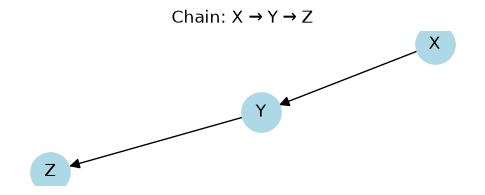

In [5]:
# --- Build the chain X -> Y -> Z ---
chain = nx.DiGraph()
chain.add_edges_from([("X", "Y"), ("Y", "Z")])

draw_graph(chain, title="Chain: X → Y → Z")
plt.show()


In [ ]:
# Part B: a fresh RNG stream (independent of Part A)
rng = np.random.default_rng(42)

X, column_mapping = generate_linear_data(
    chain, n_samples=100, rng=rng,
    coefficients={("X", "Y"): 2.0, ("Y", "Z"): 0.5},
)
print(f"X shape: {X.shape}")
print(f"column_mapping: {column_mapping}")


In [8]:
dgp = OlsDGP(chain, column_mapping).fit(X.copy())

gen = CausalMissingnessGenerator(random_generator=np.random.default_rng(0), dgp=dgp)

### MCAR: a value-blind selector

`BernoulliSelector(node, rate=...)` — each row is affected independently
with probability `rate`.


In [9]:
from badgers.core.selectors import BernoulliSelector, TopQuantileSelector

Xt, yt = gen.generate(
    X.copy(), y=None,
    perturbation_nodes=["Y"],
    selector=BernoulliSelector("Y", rate=0.5, rng=gen.random_generator),
)
print(f"rows with a NaN: {np.isnan(Xt).any(axis=1).sum()} / {len(Xt)}")

rows with a NaN: 44 / 100


### MNAR: values drive their own missingness

With the *self*-mode `TopQuantileSelector`, the **largest values of Y
itself** are the ones that go missing (here the top 30%):

missing rate: 0.30 (target: 0.30)
mean of observed Y: -1.03 vs original -0.11


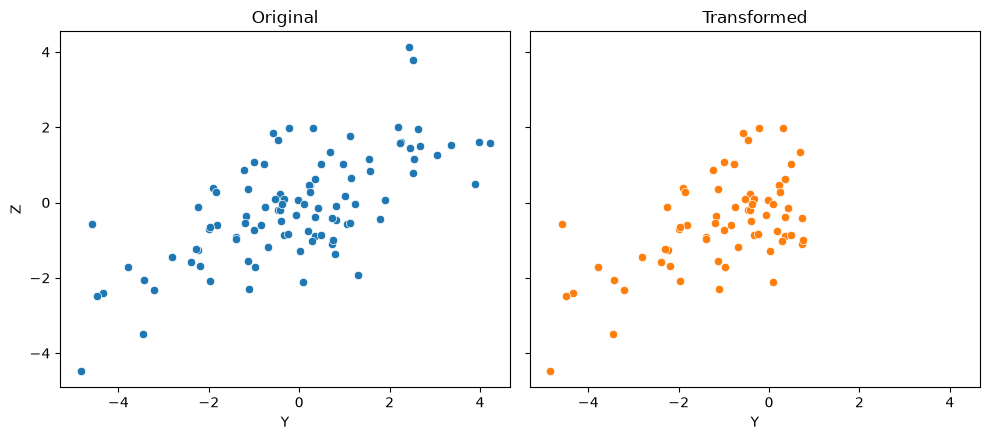

In [12]:
Xt_mnar, yt_mnar = gen.generate(
    X.copy(), y=None,
    perturbation_nodes=["Y"],
    selector=TopQuantileSelector("Y", column_mapping, quantile=0.7),
)
mask = np.isnan(Xt_mnar[:, 1])
print(f"missing rate: {mask.mean():.2f} (target: 0.30)")
print(f"mean of observed Y: {Xt_mnar[~mask, 1].mean():.2f} vs original {X[:, 1].mean():.2f}")
_ = plot_2panel(X, Xt_mnar, yt_mnar, x_idx=1, y_idx=2, x_name='Y', y_name='Z')

### MAR: a fully-observed reference column

With *reference*-mode `TopQuantileSelector`, missingness of **Y** is
driven by the observed value of **X** (the top half of X values):

rows with a NaN (rule='all'): 11 / 100


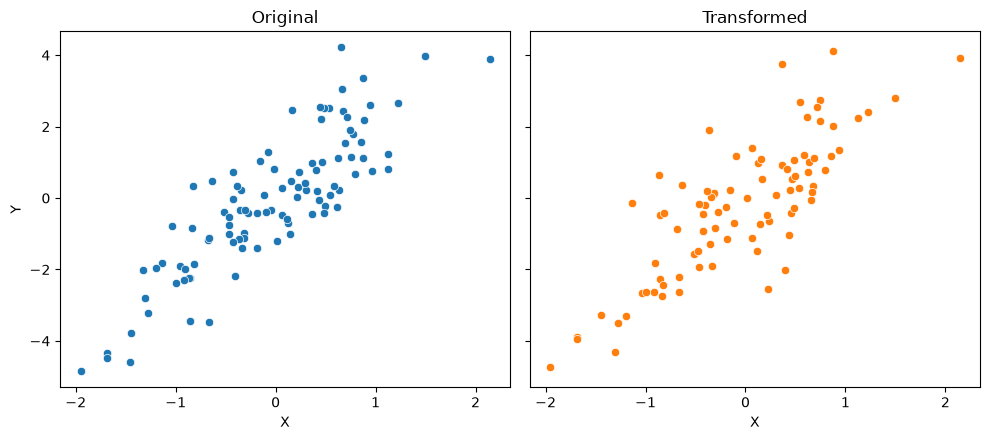

In [13]:
Xt_mar, yt_mar = gen.generate(
    X.copy(), y=None,
    perturbation_nodes=["Y"],
    selector=TopQuantileSelector("Y", column_mapping, quantile=0.5, drivers="X"),
)
x = Xt_mar[:, 0]
mask = np.isnan(Xt_mar[:, 1])
print(f"missing rate where X is high: {mask[x >= np.quantile(x, 0.75)].mean():.2f}")
print(f"missing rate where X is low:  {mask[x <= np.quantile(x, 0.25)].mean():.2f}")
_ = plot_2panel(X, Xt_mar, yt_mar, x_idx=0, y_idx=1, x_name='X', y_name='Y')

## Summary

| Lever | Generator | Uses a DGP? | Propagates? | Mechanism knob |
|---|---|---|---|---|
| observation process (legacy) | `MissingCompletelyAtRandom` | no | no | class = MCAR, `percentage_missing` = amount |
| observation process (legacy) | `DummyMissingAtRandom` | no | no | class = MAR, `percentage_missing` = amount |
| observation process (legacy) | `DummyMissingNotAtRandom` | no | no | class = MNAR, `percentage_missing` = amount |
| selectors on a causal graph | `CausalMissingnessGenerator` | **yes** (fitted) | **no** (observation layer) | selector object = mechanism **and** intensity |
* With the selector version, intensity (`rate` / `quantile`) is
  configured on the selector, not on `generate()`.
* Missingness never cascades: it is a property of the measurement,
  not of the data-generating process.
* Generators mutate `X` in place — pass `X.copy()` to keep the
  original.
